In [1]:

from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

PROJECT_ROOT = Path.cwd()

# Also work if the notebook starts inside notebooks/
if not (PROJECT_ROOT / "bovine_breeds_metadata.csv").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

CSV_PATH = PROJECT_ROOT / "bovine_breeds_metadata.csv"

DATASET_DIR = (
    PROJECT_ROOT
    / "Indian_bovine_breeds"
    / "Indian_bovine_breeds"
)

df = pd.read_csv(CSV_PATH)

print("Project root:", PROJECT_ROOT)
print("Dataset directory exists:", DATASET_DIR.exists())
print("Metadata shape:", df.shape)
print("Columns:", df.columns.tolist())

df.head()


ModuleNotFoundError: No module named 'pandas'

In [2]:
%pip install pandas numpy matplotlib pillow

Defaulting to user installation because normal site-packages is not writeable
  Using cached matplotlib-3.10.9-cp310-cp310-win_amd64.whl.metadata (52 kB)
  Using cached contourpy-1.3.2-cp310-cp310-win_amd64.whl.metadata (5.5 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
    --------------------------------------- 0.3/11.3 MB ? eta -:--:--
    --------------------------------------- 0.3/11.3 MB ? eta -:--:--
    --------------------------------------- 0.3/11.3 MB ? eta -:--:--
    --------------------------------------- 0.3/11.3 MB ? eta -:--:--
    --------------------------------------- 0.3/11.3 MB ? eta -:--:--
   - -------------------------------------- 0.5/11.3 MB 262.1 kB/s eta 0:00:42
   -- ------------------------------------- 0.8/11.3 MB 381.3 kB/s eta 0

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [3]:

from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

PROJECT_ROOT = Path.cwd()

# Also work if the notebook starts inside notebooks/
if not (PROJECT_ROOT / "bovine_breeds_metadata.csv").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

CSV_PATH = PROJECT_ROOT / "bovine_breeds_metadata.csv"

DATASET_DIR = (
    PROJECT_ROOT
    / "Indian_bovine_breeds"
    / "Indian_bovine_breeds"
)

df = pd.read_csv(CSV_PATH)

print("Project root:", PROJECT_ROOT)
print("Dataset directory exists:", DATASET_DIR.exists())
print("Metadata shape:", df.shape)
print("Columns:", df.columns.tolist())

df.head()


Project root: d:\major\project
Dataset directory exists: True
Metadata shape: (5948, 4)
Columns: ['image_id', 'breed', 'path', 'file extension']


,image_id,breed,path,file extension
0,Alambadi_1.png,Alambadi,Alambadi\Alambadi_1.png,png
1,Alambadi_10.png,Alambadi,Alambadi\Alambadi_10.png,png
2,Alambadi_100.jpg,Alambadi,Alambadi\Alambadi_100.jpg,jpg
3,Alambadi_101.png,Alambadi,Alambadi\Alambadi_101.png,png
4,Alambadi_11.png,Alambadi,Alambadi\Alambadi_11.png,png


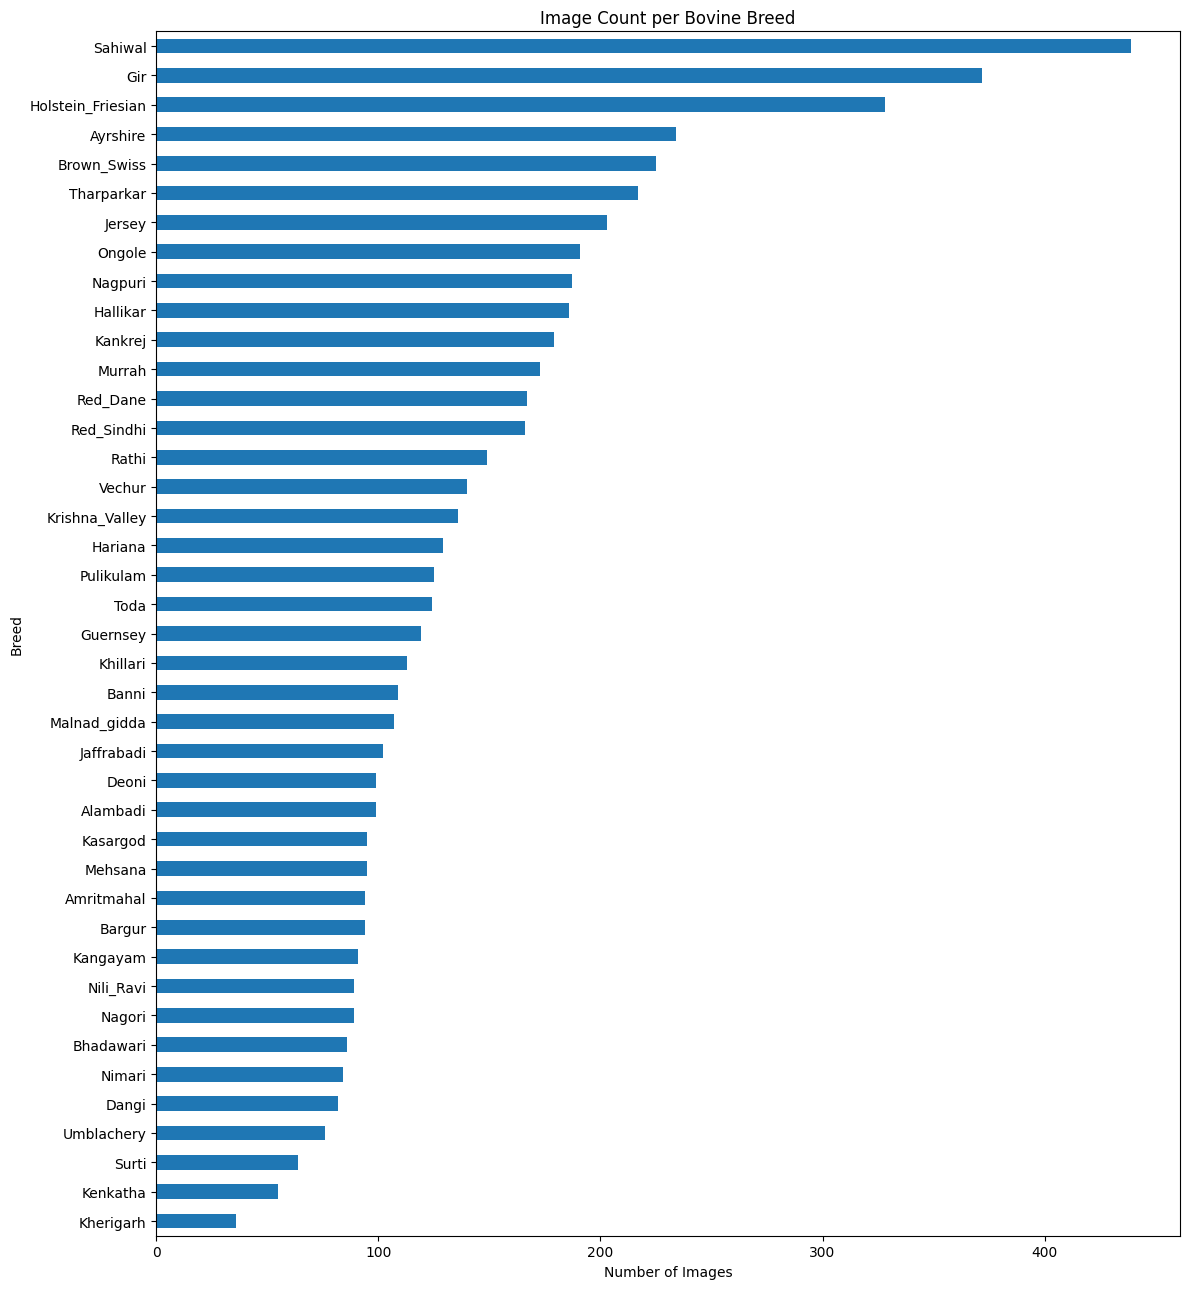

Maximum images: 439
Minimum images: 36
Mean images per breed: 145.07


In [4]:

breed_counts = df["breed"].value_counts().sort_values()

plt.figure(figsize=(12, 13))
breed_counts.plot(kind="barh")

plt.title("Image Count per Bovine Breed")
plt.xlabel("Number of Images")
plt.ylabel("Breed")
plt.tight_layout()
plt.show()

print("Maximum images:", breed_counts.max())
print("Minimum images:", breed_counts.min())
print("Mean images per breed:", round(breed_counts.mean(), 2))


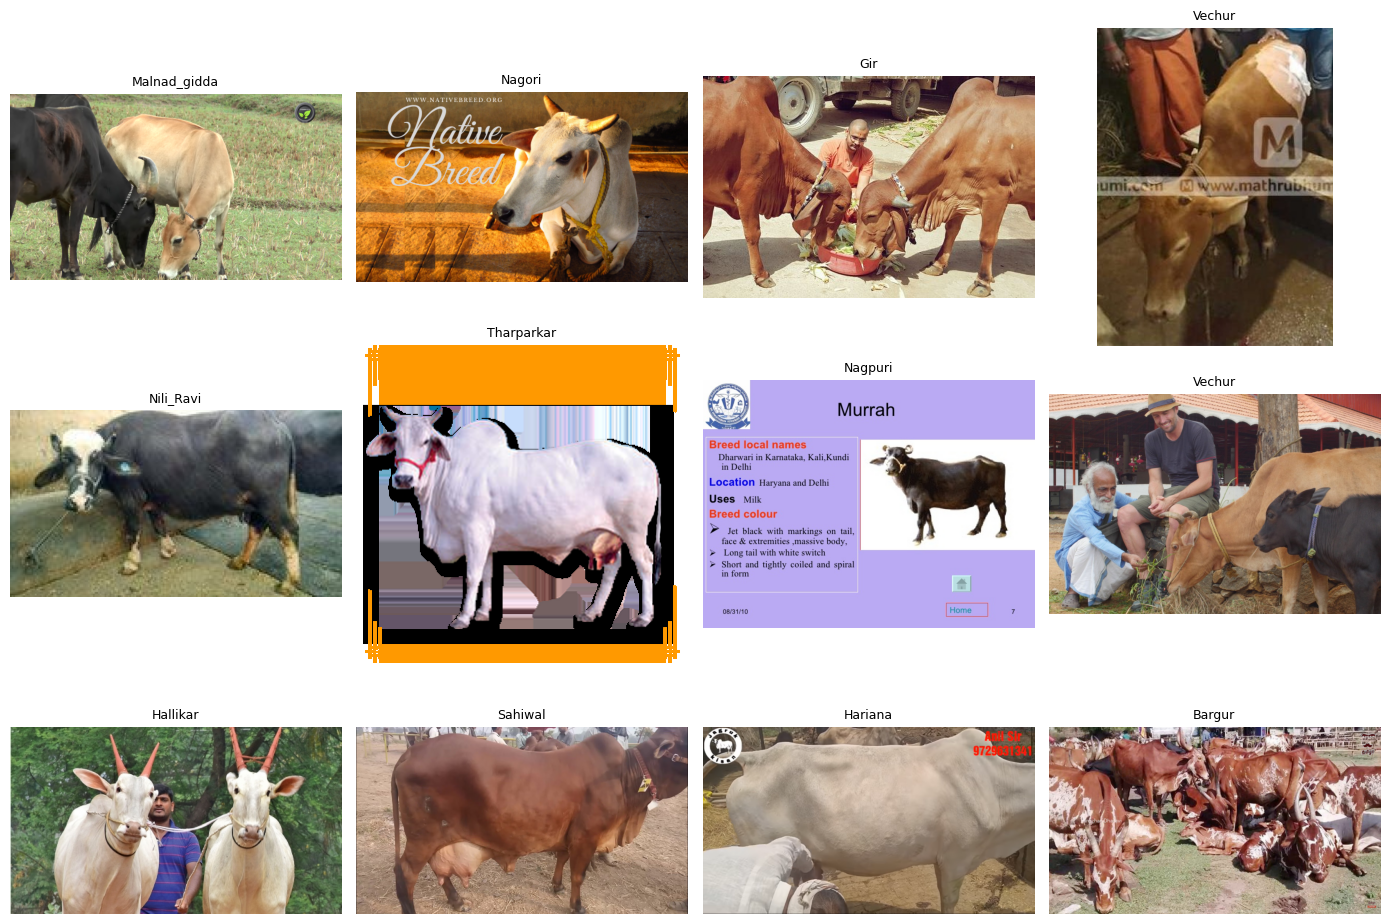

In [5]:

sample_df = df.sample(
    n=min(12, len(df)),
    random_state=42
).reset_index(drop=True)

fig, axes = plt.subplots(3, 4, figsize=(14, 10))
axes = axes.flatten()

for ax, row in zip(axes, sample_df.itertuples(index=False)):
    image_path = DATASET_DIR / str(row.path)

    with Image.open(image_path) as img:
        img.seek(0)  # First frame if the image is animated
        image = img.convert("RGB")

    ax.imshow(image)
    ax.set_title(str(row.breed), fontsize=9)
    ax.axis("off")

for ax in axes[len(sample_df):]:
    ax.axis("off")

plt.tight_layout()
plt.show()


In [6]:

dimensions = []

for row in df.itertuples(index=False):
    image_path = DATASET_DIR / str(row.path)

    with Image.open(image_path) as img:
        img.seek(0)
        width, height = img.size

    dimensions.append({
        "breed": row.breed,
        "width": width,
        "height": height,
        "format": image_path.suffix.lower()
    })

image_info = pd.DataFrame(dimensions)

print(image_info[["width", "height"]].describe())
print("\nMost common dimensions:")
print(
    image_info.groupby(["width", "height"])
    .size()
    .sort_values(ascending=False)
    .head(10)
)

print("\nFormats:")
print(image_info["format"].value_counts())


             width       height
count  5948.000000  5948.000000
mean    810.372058   536.048420
std     738.161759   467.359418
min     125.000000    83.000000
25%     275.000000   194.000000
50%     500.000000   360.000000
75%    1280.000000   749.000000
max    6016.000000  5713.000000

Most common dimensions:
width  height
1920   1080      933
1280   720       285
275    183       214
259    194       212
480    360       129
225    225       115
300    168        98
320    180        90
200    200        80
500    500        72
dtype: int64

Formats:
format
.jpg     4489
.png     1325
.jpeg     112
.gif       21
.webp       1
Name: count, dtype: int64
